In [1]:
import pandas as pd
import numpy as np
import scanpy as sc
import os
import sys
import matplotlib.pyplot as plt
import seaborn as sns
import gc
import warnings
import STAGATE_pyG as STAGATE
import anndata
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ['R_HOME'] = r'C:\Program Files\R\R-4.4.2'
os.environ['R_USER'] = r'C:\Users\CLEARLOVE\.conda\envs\STG\Lib\site-packages\rpy2'


# '151507','151508','151509','151510','151669','151670','151671','151672','151673', '151674', '151675', '151676'
section_list = ['151673', '151674', '151675', '151676']

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import annd

In [2]:
def load_DLPFC(root_dir=r'C:\Code\Data\DLPFC', section_id='151507'):
    # 151507, ..., 151676 12 in total
    ad = sc.read_visium(path=os.path.join(root_dir, section_id), count_file='filtered_feature_bc_matrix.h5', load_images=True)
    ad.var_names_make_unique()

    gt_dir = os.path.join(root_dir, section_id, 'gt')
    gt_df = pd.read_csv(os.path.join(gt_dir, 'tissue_positions_list_GTs.txt'), sep=',', header=None, index_col=0)
    ad.obs['original_clusters'] = gt_df.loc[:, 6]
    keep_bcs = ad.obs.dropna().index
    ad = ad[keep_bcs].copy()
    ad.obs['original_clusters'] = ad.obs['original_clusters'].astype(int).astype(str)
    # print(ad.obs)
    return ad

In [3]:
adata_list = {}
for section_id in section_list:
    input_dir = os.path.join('C:\Code\Data\DLPFC')
    temp_adata = load_DLPFC(root_dir=input_dir, section_id=section_id)
    temp_adata.var_names_make_unique()

    temp_adata.obs_names = [x+'_'+section_id for x in temp_adata.obs_names]

    adata_list[section_id] = temp_adata.copy()

C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
C:\Users\CLEARLOVE\.conda\envs\STG\lib\site-packages\anndata\_core\anndata.py:1758: UserWarning: Variable names are not unique. To m

------Calculating spatial graph...
The graph contains 21038 edges, 3611 cells.
5.8261 neighbors per cell on average.
------Calculating spatial graph...


C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))
C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))


The graph contains 21134 edges, 3635 cells.
5.8140 neighbors per cell on average.
------Calculating spatial graph...


C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))
C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))


The graph contains 20688 edges, 3566 cells.
5.8015 neighbors per cell on average.
------Calculating spatial graph...


C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))
C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))


The graph contains 19966 edges, 3431 cells.
5.8193 neighbors per cell on average.


C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))
C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))


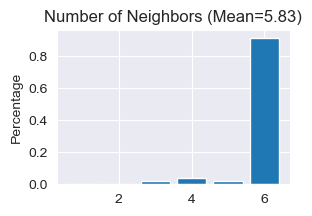

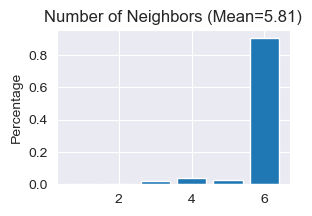

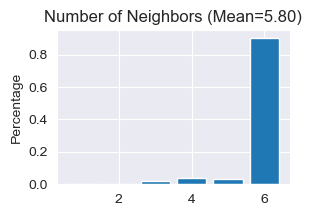

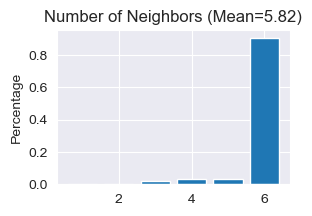

In [4]:
for section_id in section_list:
    STAGATE.Cal_Spatial_Net(adata_list[section_id], rad_cutoff=150)
    STAGATE.Stats_Spatial_Net(adata_list[section_id])

C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))
C:\Code\STG3Net-main\STAGATE_pyG\utils.py:194: FutureWarning: pandas.value_counts is deprecated and will be removed in a future version. Use pd.Series(obj).value_counts() instead.
  plot_df = pd.value_counts(pd.value_counts(adata.uns['Spatial_Net']['Cell1']))


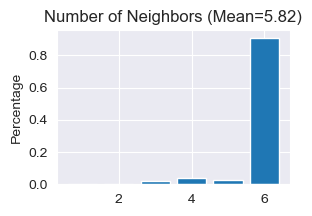

In [5]:
adata = sc.concat([adata_list[x] for x in section_list], keys=None)
adata.uns['Spatial_Net'] = pd.concat([adata_list[x].uns['Spatial_Net'] for x in section_list])
STAGATE.Stats_Spatial_Net(adata)

In [6]:
#Normalization
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=3000)
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

adata = STAGATE.train_STAGATE(adata)

Size of Input:  (14243, 3000)


100%|██████████| 1000/1000 [00:28<00:00, 34.90it/s]


In [7]:
num_cluster = 5 if section_list == ['151669', '151670', '151671', '151672'] else 7

sc.pp.neighbors(adata, use_rep='STAGATE')
sc.tl.umap(adata)
adata = STAGATE.mclust_R(adata, used_obsm='STAGATE', num_cluster=num_cluster)

R[write to console]:                    __           __ 
   ____ ___  _____/ /_  _______/ /_
  / __ `__ \/ ___/ / / / / ___/ __/
 / / / / / / /__/ / /_/ (__  ) /_  
/_/ /_/ /_/\___/_/\__,_/____/\__/   version 6.1.1
Type 'citation("mclust")' for citing this R package in publications.



fitting ...
  |======================================================================| 100%


In [8]:
from sklearn.metrics import adjusted_rand_score as ari_score
method = 'mclust'

adata.obs['Sample'] = [x.split('_')[-1] for x in adata.obs_names]

In [9]:
file_name = 'STAGATE_Donor3.h5ad'
file_path = f'C:\\Code\\Answer\\DLPFC\\{file_name}'

adata.write(file_path)

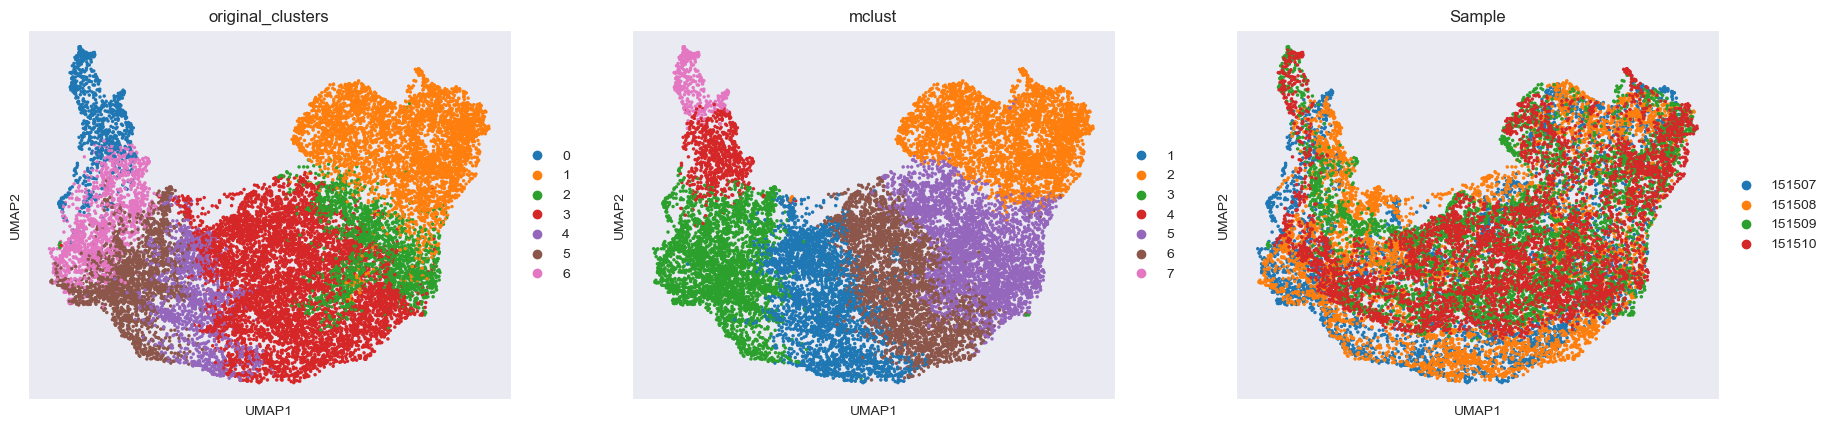

In [25]:
# %%
sc.pp.neighbors(adata, use_rep='STAGATE', metric='cosine')
sc.tl.umap(adata)
sc.pl.umap(adata, color=['original_clusters', 'mclust', 'Sample'], show=True, size=25, save=False)

In [10]:
sub_adata = adata[~pd.isnull(adata.obs['original_clusters'])]
ARI = ari_score(sub_adata.obs['original_clusters'], sub_adata.obs[method])
print(f"ARI:{ARI}")
for name in section_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['Sample'] == name]
    ARI = ari_score(sub_adata_tmp.obs['original_clusters'], sub_adata_tmp.obs['mclust'])
    print(f"{name} ARI:{ARI}")

ARI:0.5865805774142172
151673 ARI:0.5611129622697062
151674 ARI:0.6193778553181059
151675 ARI:0.5873419181979619
151676 ARI:0.590056307286529


In [27]:
from STG3Net.Metrics import compute_ARI, compute_NMI, compute_HOM, compute_COM, compute_PAS, compute_CHAOS
import pandas as pd
import harmonypy as hm

def compute_metrics(adata, true_label_key, pred_label_key):
    ari = compute_ARI(adata, true_label_key, pred_label_key)
    nmi = compute_NMI(adata, true_label_key, pred_label_key)
    hom = compute_HOM(adata, true_label_key, pred_label_key)
    com = compute_COM(adata, true_label_key, pred_label_key)
    pas = compute_PAS(adata, pred_label_key)
    chaos = compute_CHAOS(adata, pred_label_key)

    return {
        'ARI': ari,
        'NMI': nmi,
        'HOM': hom,
        'COM': com,
        'CHAOS': chaos,
        'PAS': pas
    }

# 计算整个数据集的指标
metrics_total = compute_metrics(sub_adata, 'original_clusters', 'mclust')
print("整个数据集的指标:")
for metric_name, value in metrics_total.items():
    print(f"{metric_name}: {value}")

# 计算每个切片/批次的指标
print("\n每个切片的指标:")
for name in section_list:
    sub_adata_tmp = sub_adata[sub_adata.obs['Sample'] == name]
    metrics = compute_metrics(sub_adata_tmp, 'original_clusters', 'mclust')
    print(f"\n切片 {name}:")
    for metric_name, value in metrics.items():
        print(f"{metric_name}: {value}")

整个数据集的指标:
ARI: 0.510771403590251
NMI: 0.654661821413832
HOM: 0.6629542242639467
COM: 0.6465743028558715
CHAOS: 0.0276608942732492
PAS: 0.7964970809007507

每个切片的指标:

切片 151507:
ARI: 0.49218870480171745
NMI: 0.6687925538128117
HOM: 0.6555609545725922
COM: 0.6825692790604303
CHAOS: 0.05674741342679381
PAS: 0.03885335228618811

切片 151508:
ARI: 0.48851937400555623
NMI: 0.657260403939055
HOM: 0.6553262985528584
COM: 0.6592059596109577
CHAOS: 0.05577379728514591
PAS: 0.04131476831773568

切片 151509:
ARI: 0.5570520330310729
NMI: 0.6932240885883609
HOM: 0.7191504764031088
COM: 0.6691020182001818
CHAOS: 0.05380642297611761
PAS: 0.041979949874686714

切片 151510:
ARI: 0.5134795267265321
NMI: 0.6548822332572534
HOM: 0.6756131109900289
COM: 0.6353857146875678
CHAOS: 0.055254880301268516
PAS: 0.03982589771490751


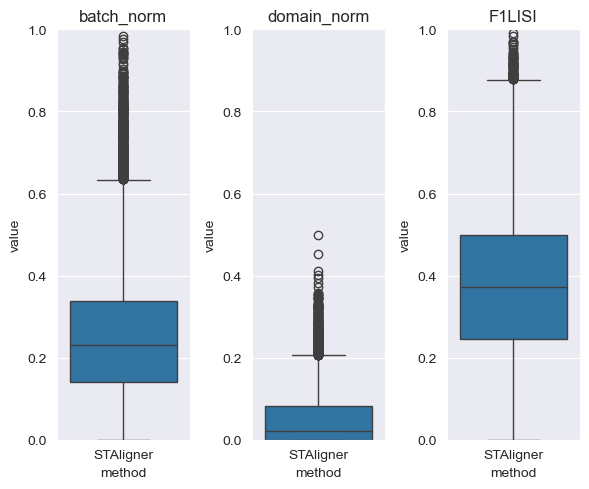

In [28]:
def compute_fscoreLISI(Tmp_adata, LT_key, BT_key, PD_key):
    num_domains = len(set(Tmp_adata.obs[PD_key])) - 1
    num_batchs = len(set(Tmp_adata.obs[BT_key])) - 1
    LISI_batch_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[BT_key]], label_colnames=[BT_key])[:, 0]
    LISI_domain_norm = hm.compute_lisi(Tmp_adata.obsm[LT_key], Tmp_adata.obs[[PD_key]], label_colnames=[PD_key])[:, 0]
    norm_batch = (LISI_batch_norm - 1)/num_batchs
    norm_domain = (LISI_domain_norm - 1)/num_domains
    LISI = 2*(1-norm_domain)*norm_batch / (1-norm_domain+norm_batch)
    return LISI , norm_batch, norm_domain

LISI , norm_batch, norm_domain = compute_fscoreLISI(sub_adata, 'STAGATE', 'Sample', 'original_clusters')

df_batch_norm = pd.DataFrame({
    'method': 'STAligner',
    'value': norm_batch,
    'type': ['batch_norm'] * len(norm_batch)
})

df_domain_norm = pd.DataFrame({
    'method': 'STAligner',
    'value': norm_domain,
    'type': ['domain_norm'] * len(norm_domain)
})

df_F1LISI = pd.DataFrame({
    'method': 'STAligner',
    'value': LISI,
    'type': ['F1LISI'] * len(LISI)
})

fig, axes = plt.subplots(1, 3, figsize=(6, 5))
sns.boxplot(data=df_batch_norm, x='method', y='value', ax=axes[0])
sns.boxplot(data=df_domain_norm, x='method', y='value', ax=axes[1])
sns.boxplot(data=df_F1LISI, x='method', y='value', ax=axes[2])
axes[0].set_ylim(0, 1)
axes[1].set_ylim(0, 1)
axes[2].set_ylim(0, 1)
axes[0].set_title('batch_norm')
axes[1].set_title('domain_norm')
axes[2].set_title('F1LISI')
plt.tight_layout()

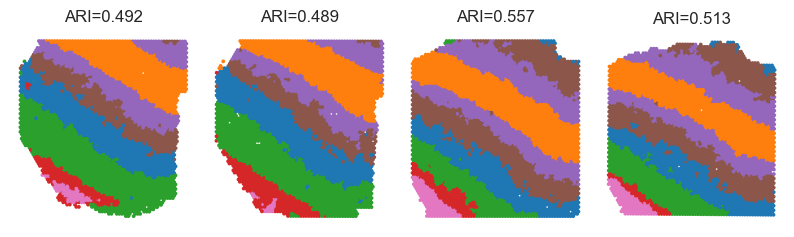

In [29]:
Batch_list = []
for section_id in section_list:
    Batch_list.append(sub_adata[sub_adata.obs['Sample'] == section_id])

spot_size = 200
title_size = 12
ARI_list = []
for bb in range(len(section_list)):
    ARI_list.append(round(ari_score(Batch_list[bb].obs['original_clusters'], Batch_list[bb].obs['mclust']), 3))

fig, ax = plt.subplots(1, 4, figsize=(10, 5), gridspec_kw={'wspace': 0.05, 'hspace': 0.1})
for idx in range(len(section_list)):
    _sc_ = sc.pl.spatial(Batch_list[idx], img_key=None, color=['mclust'], title=[''],
                      legend_loc=None, legend_fontsize=12, show=False, ax=ax[idx], frameon=False,
                      spot_size=spot_size)
    _sc_[0].set_title("ARI=" + str(ARI_list[idx]), size=title_size)
plt.show()